# IT3091 Machine Learning — Group 27
## Telco Customer Churn: Risk Prediction and High-Risk Customer Profiling

**Primary business lens:** Churn Risk  
**Secondary business lens:** High-Risk Customer Profiling  
**Task:** Supervised binary classification  
**Unit of analysis:** One customer per row  
**Target:** `Churn` (`No = 0`, `Yes = 1`)

### Purpose of this notebook
This notebook documents the end-to-end workflow for the IT3091 Guided Data Track: data understanding, evidence-based EDA, data cleaning, feature engineering, leakage-safe preprocessing, a baseline and alternative models, cross-validation, hyperparameter tuning, model selection, final evaluation, model interpretation, recommendations, limitations, and reproducibility.

### Methodological guardrails
- Candidate models and hyperparameters are compared using **training-set cross-validation only**. The selection rule is declared before evaluating the hold-out set.
- The hold-out set is used for the selected model's final evaluation and for clearly labelled, post-selection descriptive interpretation (permutation importance and risk profiling). Those descriptive analyses must not be used to select a different model, tune hyperparameters, or revise the decision rule.
- ROC-AUC is the pre-declared selection metric. Average Precision (AP) is also reported because churn is the minority class. No single metric is sufficient to establish business usefulness.

## 1. Business framing and research questions

A telecommunications provider wants to reduce customer loss and improve retention decisions. The project uses churn-risk prediction to support the identification of customers who may warrant retention review.

- **Primary lens — Churn Risk:** estimate whether a customer is likely to churn and compare classifiers using metrics relevant to identifying churners and ranking predicted risk.
- **Secondary lens — High-Risk Customer Profiling:** describe characteristics associated with customers receiving higher predicted risk. This supports interpretation of the primary output; it is not a separate prediction task and does not establish causation.
- **Main analytical question:** How well can historical customer, service, contract and billing information distinguish customers who churn from those who do not, and what descriptive patterns appear among customers receiving higher predicted risk?
- **Business caution:** the dataset does not measure the causal effect or cost of retention interventions. Predictions should support human review, not automatic decisions or claims that an intervention will prevent churn.

## 2. Dataset

The standard file contains 7,043 customer rows and 21 columns. Each row represents one customer.

In [2]:
import hashlib
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    make_scorer,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC

RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

In [9]:
from google.colab import files

# Upload the dataset
uploaded = files.upload()

# Get the uploaded filename
dataset_path = next(iter(uploaded))

# Calculate the dataset fingerprint
file_bytes = uploaded[dataset_path]
dataset_sha256 = hashlib.sha256(file_bytes).hexdigest()

# Load the dataset
df_raw = pd.read_csv(dataset_path)

# Display dataset information
print("\nSHA-256:", dataset_sha256)
print("\nDataset shape:", df_raw.shape)

display(df_raw.head())

Saving WA_Fn-UseC_-Telco-Customer-Churn.csv to WA_Fn-UseC_-Telco-Customer-Churn (2).csv

SHA-256: 88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
# Validate the dataset
required_columns = {
    "customerID", "gender", "SeniorCitizen", "Partner", "Dependents",
    "tenure", "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "Contract", "PaperlessBilling",
    "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn"
}

missing_columns = required_columns - set(df_raw.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

print("Schema validation passed!")
print("\nDataset shape:", df_raw.shape)
print("\nTarget variable: Churn")

Schema validation passed!

Dataset shape: (7043, 21)

Target variable: Churn


### Dataset scope and source verification

Each row represents a customer, and `Churn` is the labelled outcome. The public dataset is commonly distributed as the IBM Telco Customer Churn sample; this notebook records the exact file hash so our group can verify the specific CSV used. Check any version, row count or category differences rather than silently assuming all copies are identical.

## 3. Data understanding and quality checks

Start by checking row and column counts, variable types, descriptive statistics, missingness and duplicate records. These checks establish what each observation represents and identify issues that could affect preprocessing.

In [11]:
print("Dataset shape:", df_raw.shape)
print("\nFirst five rows:")
display(df_raw.head())
print("\nColumn data types and non-null counts:\n")
df_raw.info()

Dataset shape: (7043, 21)

First five rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Column data types and non-null counts:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  P

In [16]:
# Display descriptive statistics
print("Descriptive Statistics:\n")
display(df_raw.describe(include="all").T)

# Check for missing values
print("\nMissing Values:")
missing_values = df_raw.isnull().sum()
display(missing_values[missing_values > 0])

Descriptive Statistics:



,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Missing Values:


,0


In [19]:
# Convert a copy of TotalCharges to numeric so blank/non-numeric strings become visible as NaN.
df_eda = df_raw.copy()
df_eda["TotalCharges"] = pd.to_numeric(df_eda["TotalCharges"], errors="coerce")
missing_total = df_eda["TotalCharges"].isna()

print("TotalCharges missing after numeric conversion:", int(missing_total.sum()))
if missing_total.any():
    display(df_eda.loc[missing_total, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]])

    print("Tenure values for affected rows:")
    display(df_eda.loc[missing_total, "tenure"].value_counts(dropna=False).to_frame("Count"))

    print("Churn values for affected rows:")
    display(df_eda.loc[missing_total, "Churn"].value_counts(dropna=False).to_frame("Count"))

TotalCharges missing after numeric conversion: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


Tenure values for affected rows:


,Count
tenure,
0,11


Churn values for affected rows:


,Count
Churn,
No,11


In [21]:
duplicate_rows = int(df_raw.duplicated().sum())
duplicate_customer_ids = int(df_raw["customerID"].duplicated().sum())
print("Exact duplicate rows:", duplicate_rows)
print("Duplicate customer IDs:", duplicate_customer_ids)

Exact duplicate rows: 0
Duplicate customer IDs: 0


Target counts:


,Customers,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


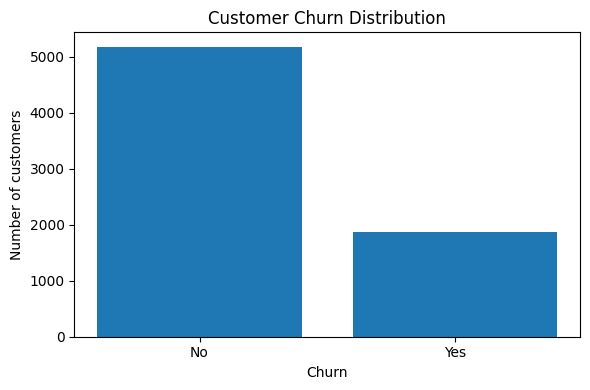

Interpretation: use stratified splitting and report more than accuracy because the churn class is the minority class.


In [22]:
print("Target counts:")
target_counts = df_raw["Churn"].value_counts(dropna=False).rename_axis("Churn").to_frame("Customers")
target_counts["Percentage"] = (target_counts["Customers"] / len(df_raw) * 100).round(2)
display(target_counts)

plt.figure(figsize=(6, 4))
churn_plot_counts = df_raw["Churn"].value_counts().reindex(["No", "Yes"], fill_value=0)
plt.bar(churn_plot_counts.index, churn_plot_counts.values)
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

print("Interpretation: use stratified splitting and report more than accuracy because the churn class is the minority class.")

In [23]:
# Inspect meaningful categorical levels (customerID is an identifier, not an analytical category).
for column in ["Contract", "InternetService", "PaymentMethod", "MultipleLines", "OnlineSecurity", "PhoneService"]:
    print(f"\n{column} — observed categories and counts")
    display(df_raw[column].value_counts(dropna=False).rename_axis(column).to_frame("Count"))


Contract — observed categories and counts


,Count
Contract,
Month-to-month,3875
Two year,1695
One year,1473



InternetService — observed categories and counts


,Count
InternetService,
Fiber optic,3096
DSL,2421
No,1526



PaymentMethod — observed categories and counts


,Count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


... (2 outputs left out)


OnlineSecurity — observed categories and counts


,Count
OnlineSecurity,
No,3498
Yes,2019
No internet service,1526



PhoneService — observed categories and counts


,Count
PhoneService,
Yes,6361
No,682


In [26]:
numeric_eda_columns = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
display(df_eda[numeric_eda_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80


## 4. Exploratory data analysis (EDA)

The following cross-tabulations report the **observed churn rate within each category**. These are descriptive associations; they do not establish that a service, contract or payment method causes churn.

In [28]:
categorical_churn_columns = ["Contract", "InternetService", "PaymentMethod"]
churn_rate_tables = {}

for column in categorical_churn_columns:
    crosstab = pd.crosstab(df_eda[column], df_eda["Churn"], normalize="index").mul(100).round(2)
    churn_rate_tables[column] = crosstab
    print(f"\n{column} × Churn (row-normalised percentages)")
    display(crosstab)
    if "Yes" in crosstab.columns:
        print("Observed churn rate by category (%):")
        display(crosstab["Yes"].sort_values(ascending=False).to_frame("Churn rate (%)"))


Contract × Churn (row-normalised percentages)


Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


Observed churn rate by category (%):


,Churn rate (%)
Contract,
Month-to-month,42.71
One year,11.27
Two year,2.83



InternetService × Churn (row-normalised percentages)


Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


... (2 outputs left out)


PaymentMethod × Churn (row-normalised percentages)


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


Observed churn rate by category (%):


,Churn rate (%)
PaymentMethod,
Electronic check,45.29
Mailed check,19.11
Bank transfer (automatic),16.71
Credit card (automatic),15.24


,Customer_count,Mean,Median,Minimum,Maximum
Churn,,,,,
No,5174,37.57,38.0,0,72
Yes,1869,17.98,10.0,1,72


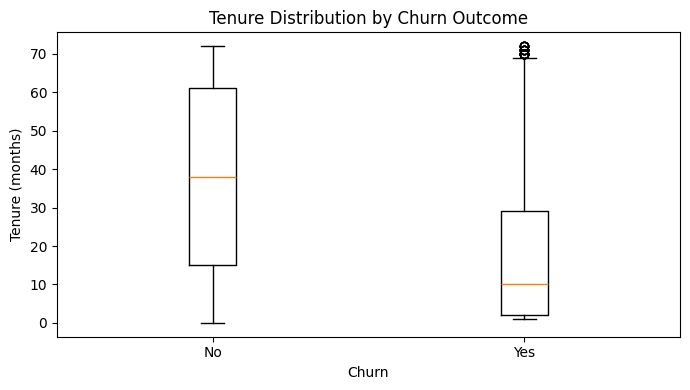


Interpretation: compare group-level tenure distributions; do not claim tenure alone causes churn.


In [30]:
tenure_by_churn = df_eda.groupby("Churn")["tenure"].agg(
    Customer_count="count", Mean="mean", Median="median", Minimum="min", Maximum="max"
).round(2)
display(tenure_by_churn)

fig, ax = plt.subplots(figsize=(7, 4))
tenure_no = df_eda.loc[df_eda["Churn"] == "No", "tenure"].dropna().to_numpy()
tenure_yes = df_eda.loc[df_eda["Churn"] == "Yes", "tenure"].dropna().to_numpy()
ax.boxplot([tenure_no, tenure_yes])
ax.set_xticks([1, 2], labels=["No", "Yes"])
ax.set_title("Tenure Distribution by Churn Outcome")
ax.set_xlabel("Churn")
ax.set_ylabel("Tenure (months)")
plt.tight_layout()
plt.show()

print("\nInterpretation: compare group-level tenure distributions; do not claim tenure alone causes churn.")

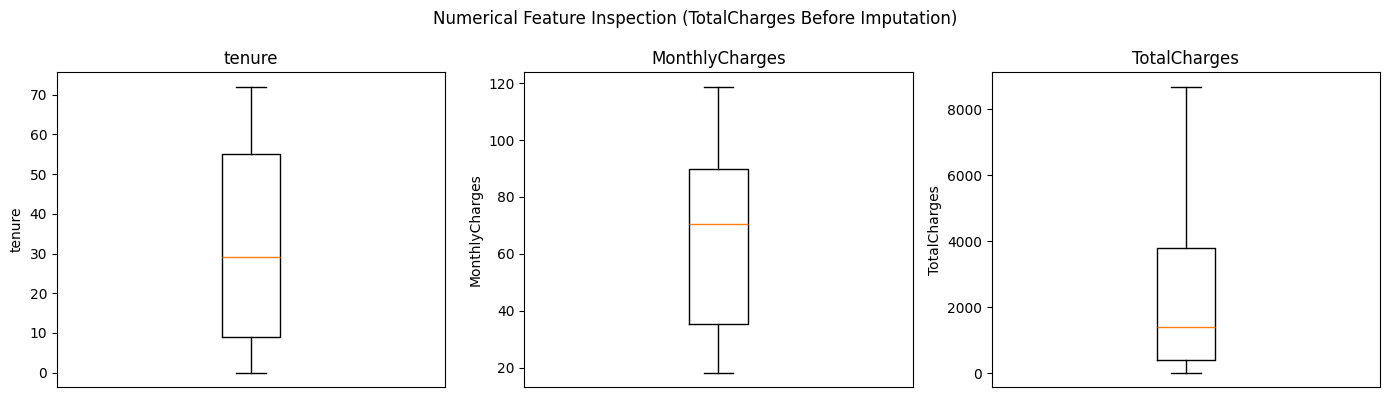


No row is removed solely because a value is flagged by a box plot. Check whether values are valid before deciding on any treatment.


In [32]:
# Box plots help flag unusual ranges. SeniorCitizen is a binary indicator and is not treated as a continuous outlier variable.
boxplot_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, len(boxplot_columns), figsize=(14, 4))
for ax, column in zip(axes, boxplot_columns):
    values = df_eda[column].dropna().to_numpy()
    ax.boxplot(values)
    ax.set_title(column)
    ax.set_xticks([])
    ax.set_ylabel(column)
plt.suptitle("Numerical Feature Inspection (TotalCharges Before Imputation)")
plt.tight_layout()
plt.show()

print("\nNo row is removed solely because a value is flagged by a box plot. Check whether values are valid before deciding on any treatment.")

### Additional EDA: customer attributes, services and billing

The next table extends the main EDA beyond contract type, internet service and payment method. It reports the number of customers and the observed churn rate within each category for selected demographic, billing and add-on service attributes. Monthly charges are also summarised separately for churn and non-churn customers.

These analyses are included to make the evidence trail more complete—not to imply that demographic or service attributes cause churn. Use the actual output generated by this run when discussing which differences appear meaningful.

Additional demographic, billing and service churn-rate table:


,Feature,Category,Customers,Observed churn rate (%)
0,Dependents,No,4933,31.28
1,Dependents,Yes,2110,15.45
2,DeviceProtection,No,3095,39.13
3,DeviceProtection,Yes,2422,22.50
4,DeviceProtection,No internet service,1526,7.40
5,OnlineBackup,No,3088,39.93
6,OnlineBackup,Yes,2429,21.53
7,OnlineBackup,No internet service,1526,7.40
8,OnlineSecurity,No,3498,41.77
9,OnlineSecurity,Yes,2019,14.61


MonthlyCharges descriptive statistics by observed churn outcome:


,Customers,Mean,Median,Minimum,Maximum
Churn,,,,,
No,5174,61.27,64.43,18.25,118.75
Yes,1869,74.44,79.65,18.85,118.35


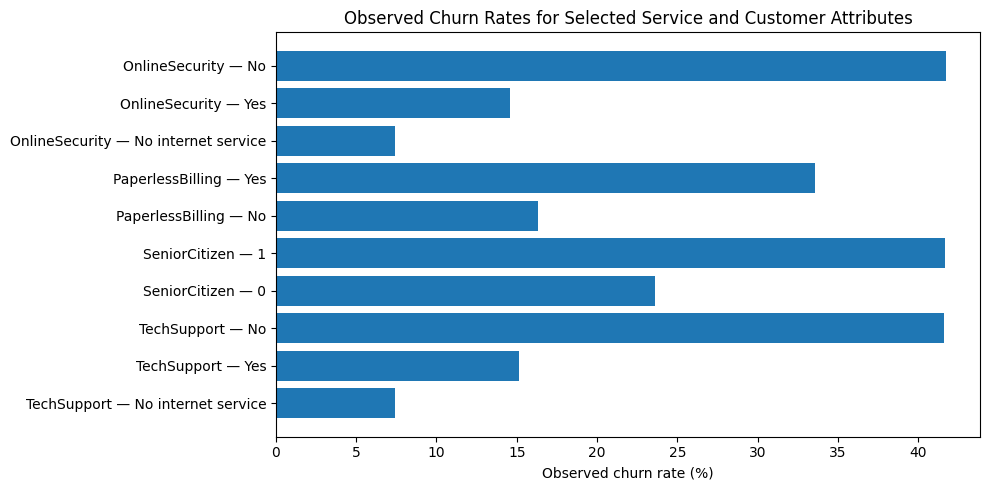

Interpret these rates descriptively. They do not establish that a feature causes churn.


In [34]:
# Additional demographic, billing and service-related EDA.
# These are descriptive associations, not causal estimates.
additional_eda_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "PaperlessBilling",
    "PhoneService", "TechSupport", "OnlineSecurity", "OnlineBackup", "DeviceProtection"
]
additional_rate_rows = []
for column in additional_eda_columns:
    category_counts = df_eda[column].value_counts(dropna=False)
    churn_rates = pd.crosstab(df_eda[column], df_eda["Churn"], normalize="index").mul(100)
    for category, count in category_counts.items():
        rate = float(churn_rates.loc[category, "Yes"]) if "Yes" in churn_rates.columns else np.nan
        additional_rate_rows.append({
            "Feature": column,
            "Category": str(category),
            "Customers": int(count),
            "Observed churn rate (%)": round(rate, 2),
        })
additional_churn_rates = pd.DataFrame(additional_rate_rows).sort_values(
    ["Feature", "Observed churn rate (%)"], ascending=[True, False]
).reset_index(drop=True)
print("Additional demographic, billing and service churn-rate table:")
display(additional_churn_rates)

monthly_charges_by_churn = df_eda.groupby("Churn")["MonthlyCharges"].agg(
    Customers="count", Mean="mean", Median="median", Minimum="min", Maximum="max"
).round(2)
print("MonthlyCharges descriptive statistics by observed churn outcome:")
display(monthly_charges_by_churn)

# Display a compact plot for selected service variables.
plot_service_features = ["TechSupport", "OnlineSecurity", "PaperlessBilling", "SeniorCitizen"]
service_plot_rows = additional_churn_rates[additional_churn_rates["Feature"].isin(plot_service_features)]
fig, ax = plt.subplots(figsize=(10, 5))
labels = service_plot_rows["Feature"] + " — " + service_plot_rows["Category"]
ax.barh(labels, service_plot_rows["Observed churn rate (%)"])
ax.set_xlabel("Observed churn rate (%)")
ax.set_title("Observed Churn Rates for Selected Service and Customer Attributes")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
print("Interpret these rates descriptively. They do not establish that a feature causes churn.")

### EDA interpretation to carry into modelling

- The target is imbalanced, so a majority-class baseline and minority-class metrics are necessary.
- `Contract`, `InternetService`, and `PaymentMethod` show different observed churn rates across categories; retain them as categorical predictors and interpret associations cautiously.
- Tenure distributions and monthly charges should be compared across observed churn groups, without causal claims.
- Additional demographic and service-related crosstabs help document which groups differ in observed churn rates; these are descriptive findings and are not used as evidence of causation.
- The raw `TotalCharges` field contains blank values that become missing after numeric conversion. All affected records are checked before treatment.
- The box plots are diagnostic only. Outlier-looking values are not automatically removed unless they are shown to be errors.
- Two candidate engineered features are added after the data-quality checks: `TenureGroup` (customer-lifecycle intervals) and `NumAdditionalServices` (number of selected add-on services). Their predictive value is assessed through training-set cross-validation, rather than assumed in advance.

The detailed rates and descriptive statistics are printed above from the exact input file used in this run.

## 5. Cleaning, feature engineering, target definition and train/test split

The 11 missing `TotalCharges` values are treated as zero only after confirming that the affected records have `tenure = 0`. This is a documented domain-based data-quality rule. `customerID` is retained separately for row reference but excluded from predictors.

Two candidate engineered features are then created from existing predictors: `TenureGroup`, a grouped representation of customer lifecycle, and `NumAdditionalServices`, a count of six selected add-on services. Neither uses `Churn` to calculate its value. Both are included as candidate predictors, and their usefulness is judged through training-only validation. The engineered features must also be recorded in the group's preprocessing/feature log.

In [35]:
df_model_full = df_eda.copy()
missing_mask = df_model_full["TotalCharges"].isna()
missing_count = int(missing_mask.sum())

if missing_count > 0:
    if not (df_model_full.loc[missing_mask, "tenure"] == 0).all():
        raise ValueError("Some missing TotalCharges records do not have tenure=0. Reconsider the zero-imputation rule.")
    df_model_full.loc[missing_mask, "TotalCharges"] = 0.0

print("TotalCharges missing after documented treatment:", int(df_model_full["TotalCharges"].isna().sum()))
print("Dataset shape after cleaning:", df_model_full.shape)
print("customerID remains available for profiling but will not be a model feature.")

# Candidate engineered feature 1: tenure group to represent customer-lifecycle stage.
tenure_bins = [-1, 12, 24, 48, 60, 72]
tenure_labels = ["0-12 months", "13-24 months", "25-48 months", "49-60 months", "61-72 months"]
df_model_full["TenureGroup"] = pd.cut(
    df_model_full["tenure"], bins=tenure_bins, labels=tenure_labels, include_lowest=True
)

# Candidate engineered feature 2: count of subscribed add-on service features.
additional_service_columns = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"
]
df_model_full["NumAdditionalServices"] = (
    df_model_full[additional_service_columns].eq("Yes").sum(axis=1).astype("int64")
)

if df_model_full["TenureGroup"].isna().any():
    raise ValueError("Some tenure values could not be assigned to a TenureGroup. Inspect tenure before modelling.")

engineered_feature_summary = pd.DataFrame({
    "Feature": ["TenureGroup", "NumAdditionalServices"],
    "Purpose": [
        "Categorical customer-lifecycle interval derived from tenure",
        "Count of subscribed add-on services derived from six service columns",
    ],
    "Missing values": [
        int(df_model_full["TenureGroup"].isna().sum()),
        int(df_model_full["NumAdditionalServices"].isna().sum()),
    ],
    "Observed levels / range": [
        ", ".join(map(str, df_model_full["TenureGroup"].cat.categories)),
        f"{int(df_model_full['NumAdditionalServices'].min())} to {int(df_model_full['NumAdditionalServices'].max())}",
    ],
})
print("Engineered feature summary:")
display(engineered_feature_summary)
print("TenureGroup distribution:")
display(df_model_full["TenureGroup"].value_counts(sort=False).rename_axis("TenureGroup").to_frame("Customers"))
print("NumAdditionalServices distribution:")
display(df_model_full["NumAdditionalServices"].value_counts().sort_index().rename_axis("NumAdditionalServices").to_frame("Customers"))

TotalCharges missing after documented treatment: 0
Dataset shape after cleaning: (7043, 21)
customerID remains available for profiling but will not be a model feature.
Engineered feature summary:


,Feature,Purpose,Missing values,Observed levels / range
0,TenureGroup,Categorical customer-lifecycle interval derive...,0,"0-12 months, 13-24 months, 25-48 months, 49-60..."
1,NumAdditionalServices,Count of subscribed add-on services derived fr...,0,0 to 6


TenureGroup distribution:


,Customers
TenureGroup,
0-12 months,2186
13-24 months,1024
25-48 months,1594
49-60 months,832
61-72 months,1407


NumAdditionalServices distribution:


,Customers
NumAdditionalServices,
0,2219
1,966
2,1033
3,1118
4,852
5,571
6,284


In [36]:
# Define the binary target and predictors.
customer_ids = df_model_full["customerID"].copy()
y = df_model_full["Churn"].map({"No": 0, "Yes": 1})
if y.isna().any():
    raise ValueError("Unexpected/missing labels found in Churn; inspect the target values before proceeding.")

X = df_model_full.drop(columns=["customerID", "Churn"])

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)
print("Target values:", sorted(y.unique().tolist()))
print("Target distribution:")
display(y.value_counts().sort_index().rename(index={0: "No Churn (0)", 1: "Churn (1)"}).to_frame("Count"))

Predictor shape: (7043, 21)
Target shape: (7043,)
Target values: [0, 1]
Target distribution:


,Count
Churn,
No Churn (0),5174
Churn (1),1869


In [37]:
# Split before fitting any preprocessing or model. Stratification preserves class proportions.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Training target proportions (%):")
display((y_train.value_counts(normalize=True).sort_index() * 100).round(2).to_frame("Percentage"))
print("Test target proportions (%):")
display((y_test.value_counts(normalize=True).sort_index() * 100).round(2).to_frame("Percentage"))

Training shape: (5634, 21) | Test shape: (1409, 21)
Training target proportions (%):


,Percentage
Churn,
0,73.46
1,26.54


Test target proportions (%):


,Percentage
Churn,
0,73.46
1,26.54


In [38]:
# Identifying column types does not fit a transformation; all learned transformations are fitted inside pipelines.
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("Number of numeric predictors:", len(numerical_features))
print("Number of categorical predictors:", len(categorical_features))
print("Engineered predictors included:", ["TenureGroup", "NumAdditionalServices"])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ],
    remainder="drop",
)

# A separate diagnostic copy checks dimensions without fitting the template used by the model pipelines.
preprocessor_check = clone(preprocessor)
X_train_check = preprocessor_check.fit_transform(X_train)
X_test_check = preprocessor_check.transform(X_test)
print("Diagnostic transformed train shape:", X_train_check.shape)
print("Diagnostic transformed test shape:", X_test_check.shape)
print("The actual models use the preprocessor inside Pipeline so each CV fold fits its own transformations.")

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'NumAdditionalServices']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TenureGroup']
Number of numeric predictors: 5
Number of categorical predictors: 16
Engineered predictors included: ['TenureGroup', 'NumAdditionalServices']
Diagnostic transformed train shape: (5634, 51)
Diagnostic transformed test shape: (1409, 51)
The actual models use the preprocessor inside Pipeline so each CV fold fits its own transformations.


## 6. Baseline and candidate models

The baseline is a majority-class `DummyClassifier`. Four alternatives are compared: Logistic Regression, Decision Tree, Random Forest and SVM. Class weighting is used for the four machine-learning classifiers because churn is the minority class. The engineered features are supplied consistently to all models so their cross-validation comparison uses the same predictor set. The baseline and candidates are evaluated using training-only cross-validation before any final test-set evaluation.

In [39]:
from sklearn.base import clone
from sklearn.metrics import make_scorer

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
precision_scorer = make_scorer(precision_score, zero_division=0)
scoring = {
    "accuracy": "accuracy",
    "precision": precision_scorer,
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "average_precision": "average_precision",
}

baseline_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", DummyClassifier(strategy="most_frequent")),
])

candidate_models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE)),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=1)),
    ]),
    "SVM": Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=RANDOM_STATE)),
    ]),
}

print("Baseline and four candidate pipelines created.")
print("CV strategy:", cv)
print("Primary tuning/refit metric: ROC-AUC. Secondary reported metrics: Average Precision, precision, recall, F1 and accuracy.")

Baseline and four candidate pipelines created.
CV strategy: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
Primary tuning/refit metric: ROC-AUC. Secondary reported metrics: Average Precision, precision, recall, F1 and accuracy.


In [40]:
# Initial cross-validation comparison: training data only. No test-set scores are calculated here.
all_initial_models = {"Dummy Baseline": baseline_pipeline, **candidate_models}
initial_cv_rows = []

for model_name, estimator in all_initial_models.items():
    print("Cross-validating:", model_name)
    scores = cross_validate(
        estimator,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False,
    )
    initial_cv_rows.append({
        "Model": model_name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Precision": scores["test_precision"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV F1": scores["test_f1"].mean(),
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV ROC-AUC SD": scores["test_roc_auc"].std(ddof=1),
        "CV Average Precision (AP)": scores["test_average_precision"].mean(),
        "CV AP SD": scores["test_average_precision"].std(ddof=1),
    })

initial_cv_results = pd.DataFrame(initial_cv_rows).sort_values("CV ROC-AUC", ascending=False).reset_index(drop=True)
print("Average Precision is included because the positive class (churn) is the minority class.")
display(initial_cv_results.round(4))

Cross-validating: Dummy Baseline
Cross-validating: Logistic Regression
Cross-validating: Decision Tree
Cross-validating: Random Forest
Cross-validating: SVM
Average Precision is included because the positive class (churn) is the minority class.


,Model,CV Accuracy,CV Precision,CV Recall,CV F1,CV ROC-AUC,CV ROC-AUC SD,CV Average Precision (AP),CV AP SD
0,Logistic Regression,0.7488,0.5174,0.7953,0.6268,0.8463,0.0127,0.6643,0.0146
1,SVM,0.7465,0.5147,0.7719,0.6175,0.8266,0.0112,0.6050,0.0258
2,Random Forest,0.7879,0.6375,0.4676,0.5393,0.8232,0.0129,0.6146,0.0342
3,Decision Tree,0.7322,0.4977,0.7933,0.6114,0.8175,0.0070,0.6100,0.0263
4,Dummy Baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.0000,0.2654,0.0001


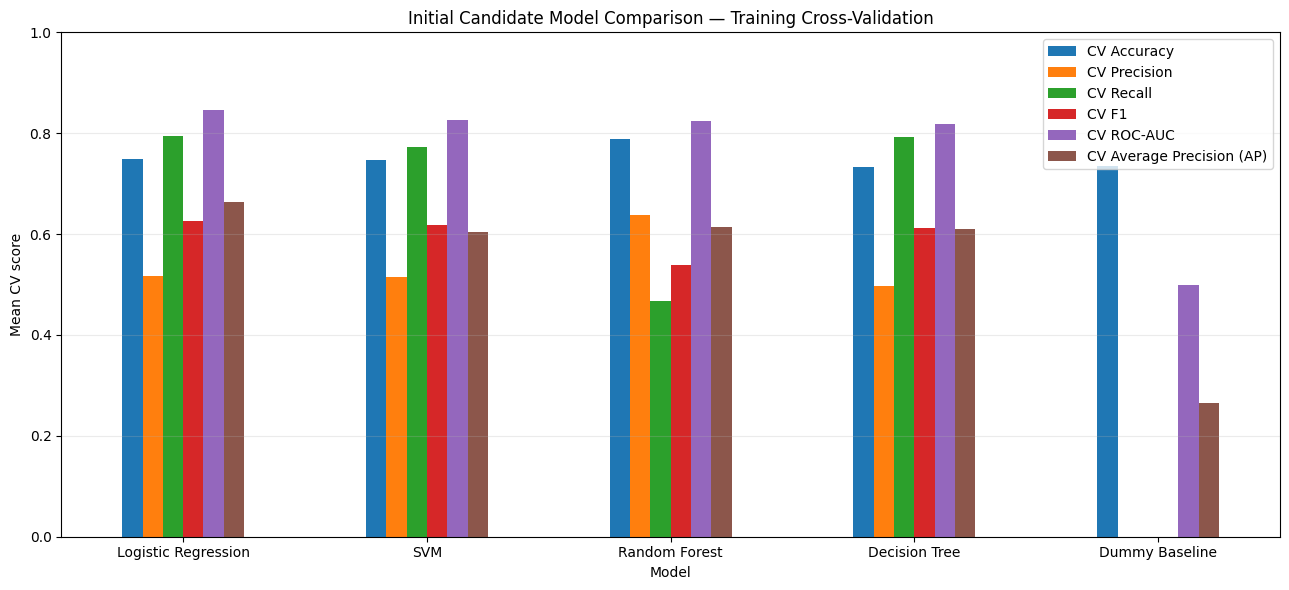

Compare AP and ROC-AUC as complementary ranking metrics; they measure related but different properties.


In [41]:
# Visual comparison using cross-validation only.
cv_plot_metrics = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1", "CV ROC-AUC", "CV Average Precision (AP)"]
plot_cv = initial_cv_results.set_index("Model")[cv_plot_metrics]
ax = plot_cv.plot(kind="bar", figsize=(13, 6))
ax.set_title("Initial Candidate Model Comparison — Training Cross-Validation")
ax.set_ylabel("Mean CV score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()
print("Compare AP and ROC-AUC as complementary ranking metrics; they measure related but different properties.")

## 7. Hyperparameter tuning with GridSearchCV

Hyperparameters are selected using five-fold stratified cross-validation on `X_train` and `y_train`. `GridSearchCV` refits the best configuration for each model family using **mean ROC-AUC** (`refit="roc_auc"`), the pre-declared selection metric. Average Precision is also recorded at each selected configuration to give another view of positive-class ranking performance. The hold-out set is not used for tuning.

In [42]:
param_grids = {
    "Logistic Regression": {
        "classifier__C": [0.1, 1, 10],
        "classifier__solver": ["lbfgs"],
    },
    "Decision Tree": {
        "classifier__max_depth": [4, 6, 8],
        "classifier__min_samples_split": [2, 5],
        "classifier__min_samples_leaf": [1, 4],
    },
    "Random Forest": {
        "classifier__n_estimators": [100, 200, 300],
        "classifier__max_depth": [6, 8],
        "classifier__min_samples_leaf": [1, 4],
    },
    "SVM": {
        "classifier__C": [0.1, 1, 10],
        "classifier__kernel": ["linear", "rbf"],
    },
}

grid_searches = {}
tuned_models = {}
tuned_cv_rows = []

for model_name, estimator in candidate_models.items():
    print(f"Tuning {model_name}...")
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grids[model_name],
        scoring=scoring,
        refit="roc_auc",
        cv=cv,
        n_jobs=-1,
        return_train_score=False,
        verbose=0,
    )
    search.fit(X_train, y_train)
    grid_searches[model_name] = search
    tuned_models[model_name] = search.best_estimator_

    best_idx = search.best_index_
    cv_res = search.cv_results_
    tuned_cv_rows.append({
        "Model": model_name,
        "Best CV Accuracy": cv_res["mean_test_accuracy"][best_idx],
        "Best CV Precision": cv_res["mean_test_precision"][best_idx],
        "Best CV Recall": cv_res["mean_test_recall"][best_idx],
        "Best CV F1": cv_res["mean_test_f1"][best_idx],
        "Best CV ROC-AUC": search.best_score_,
        "Best CV ROC-AUC SD": cv_res["std_test_roc_auc"][best_idx],
        "Best CV Average Precision (AP)": cv_res["mean_test_average_precision"][best_idx],
        "Best CV AP SD": cv_res["std_test_average_precision"][best_idx],
        "Best Parameters": search.best_params_,
        "Parameter Combinations": len(search.cv_results_["params"]),
    })
    print("  Best parameters:", search.best_params_)
    print(f"  Best mean CV ROC-AUC: {search.best_score_:.4f}")
    print(f"  Average Precision at chosen configuration: {cv_res['mean_test_average_precision'][best_idx]:.4f}")

tuned_cv_results = pd.DataFrame(tuned_cv_rows).sort_values("Best CV ROC-AUC", ascending=False).reset_index(drop=True)
print("\nTuned model comparison (all metrics are from training-data CV at the ROC-AUC-selected configuration):")
display(tuned_cv_results.round(4))

Tuning Logistic Regression...
  Best parameters: {'classifier__C': 1, 'classifier__solver': 'lbfgs'}
  Best mean CV ROC-AUC: 0.8463
  Average Precision at chosen configuration: 0.6643
Tuning Decision Tree...
  Best parameters: {'classifier__max_depth': 4, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2}
  Best mean CV ROC-AUC: 0.8279
  Average Precision at chosen configuration: 0.6000
Tuning Random Forest...
  Best parameters: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 300}
  Best mean CV ROC-AUC: 0.8479
  Average Precision at chosen configuration: 0.6628
Tuning SVM...
  Best parameters: {'classifier__C': 0.1, 'classifier__kernel': 'rbf'}
  Best mean CV ROC-AUC: 0.8367
  Average Precision at chosen configuration: 0.6420

Tuned model comparison (all metrics are from training-data CV at the ROC-AUC-selected configuration):


,Model,Best CV Accuracy,Best CV Precision,Best CV Recall,Best CV F1,Best CV ROC-AUC,Best CV ROC-AUC SD,Best CV Average Precision (AP),Best CV AP SD,Best Parameters,Parameter Combinations
0,Random Forest,0.7634,0.5384,0.7645,0.6317,0.8479,0.0097,0.6628,0.0177,"{'classifier__max_depth': 8, 'classifier__min_...",12
1,Logistic Regression,0.7488,0.5174,0.7953,0.6268,0.8463,0.0114,0.6643,0.0131,"{'classifier__C': 1, 'classifier__solver': 'lb...",3
2,SVM,0.7439,0.5112,0.7913,0.6210,0.8367,0.0114,0.6420,0.0269,"{'classifier__C': 0.1, 'classifier__kernel': '...",6
3,Decision Tree,0.7233,0.4895,0.7920,0.6030,0.8279,0.0106,0.6000,0.0217,"{'classifier__max_depth': 4, 'classifier__min_...",12


## 8. Model selection — before using the test set

**Selection rule:** select the tuned model family with the highest mean CV ROC-AUC across the specified search grids. ROC-AUC is the common tuning objective because the business use includes ranking customers by predicted churn risk. Average Precision is reported as a complementary positive-class metric; recall, precision and F1 are also considered because missed churners and unnecessary retention contacts can have different business costs.

The selection rule is applied only to training-data cross-validation results and is not changed in response to test-set results. A small difference in CV ROC-AUC should not be described as proof that one model is meaningfully superior. Fold-to-fold variability and trade-offs in recall/F1 are reported for context; the standard deviation across folds is descriptive, not a formal significance test. The best CV score may be optimistic after hyperparameter search, so the selected model's hold-out result is reported separately.

In [43]:
selected_row = tuned_cv_results.iloc[0]
selected_model_name = selected_row["Model"]
final_model = tuned_models[selected_model_name]

print("Selected model family:", selected_model_name)
print(f"Best CV ROC-AUC: {selected_row['Best CV ROC-AUC']:.4f}")
print(f"CV Average Precision at selected configuration: {selected_row['Best CV Average Precision (AP)']:.4f}")
print(f"CV Recall at selected configuration: {selected_row['Best CV Recall']:.4f}")
print(f"CV F1 at selected configuration: {selected_row['Best CV F1']:.4f}")
print("Selected hyperparameters:", selected_row["Best Parameters"])

if len(tuned_cv_results) > 1:
    runner_up = tuned_cv_results.iloc[1]
    auc_gap = float(selected_row["Best CV ROC-AUC"] - runner_up["Best CV ROC-AUC"])
    variability_reference = max(float(selected_row["Best CV ROC-AUC SD"]), float(runner_up["Best CV ROC-AUC SD"]))
    recall_gap = float(selected_row["Best CV Recall"] - runner_up["Best CV Recall"])
    f1_gap = float(selected_row["Best CV F1"] - runner_up["Best CV F1"])
    print(f"\nRunner-up by CV ROC-AUC: {runner_up['Model']}")
    print(f"CV ROC-AUC gap over runner-up: {auc_gap:.4f}")
    print(f"Difference in CV recall (selected minus runner-up): {recall_gap:+.4f}")
    print(f"Difference in CV F1 (selected minus runner-up): {f1_gap:+.4f}")
    if auc_gap < variability_reference:
        print("Caution: the ROC-AUC gap is smaller than at least one model's fold-to-fold SD. Treat the ranking conservatively; this is not a formal significance test.")
    else:
        print("The ROC-AUC gap is larger than the larger of the two fold-to-fold SDs, but this comparison is still descriptive rather than a formal significance test.")
print("The choice follows the pre-declared ROC-AUC rule; business priorities may prefer a different error trade-off after separate threshold/cost analysis.")

Selected model family: Random Forest
Best CV ROC-AUC: 0.8479
CV Average Precision at selected configuration: 0.6628
CV Recall at selected configuration: 0.7645
CV F1 at selected configuration: 0.6317
Selected hyperparameters: {'classifier__max_depth': 8, 'classifier__min_samples_leaf': 4, 'classifier__n_estimators': 300}

Runner-up by CV ROC-AUC: Logistic Regression
CV ROC-AUC gap over runner-up: 0.0015
Difference in CV recall (selected minus runner-up): -0.0308
Difference in CV F1 (selected minus runner-up): +0.0049
Caution: the ROC-AUC gap is smaller than at least one model's fold-to-fold SD. Treat the ranking conservatively; this is not a formal significance test.
The choice follows the pre-declared ROC-AUC rule; business priorities may prefer a different error trade-off after separate threshold/cost analysis.


## 9. Final held-out test evaluation

The selected tuned model is now evaluated on the stratified hold-out test set. No alternative model is evaluated on this set for model selection. Report the results below as the selected model's final hold-out evaluation; do not use them to revisit model choice or tune hyperparameters.

The same hold-out predictions also support pre-declared, post-selection checks of probability ranking/calibration and descriptive interpretation in later sections. These analyses must not be used to select a different model, tune it, or revise the declared model-selection rule.

In [44]:
y_test_pred = final_model.predict(X_test)
if not hasattr(final_model, "predict_proba"):
    raise AttributeError("The selected model does not expose predict_proba; ROC-AUC/probability metrics need a decision_function-based alternative.")
y_test_prob = final_model.predict_proba(X_test)[:, 1]

final_test_metrics = {
    "Selected model": selected_model_name,
    "Test Accuracy": accuracy_score(y_test, y_test_pred),
    "Test Precision": precision_score(y_test, y_test_pred, zero_division=0),
    "Test Recall": recall_score(y_test, y_test_pred, zero_division=0),
    "Test F1": f1_score(y_test, y_test_pred, zero_division=0),
    "Test ROC-AUC": roc_auc_score(y_test, y_test_prob),
    "Test Average Precision (AP)": average_precision_score(y_test, y_test_prob),
    "Test Brier Score": brier_score_loss(y_test, y_test_prob),
}
final_test_results = pd.DataFrame([final_test_metrics])
display(final_test_results.round(4))

print("Classification report at the estimator's default classification decision rule:")
print(classification_report(y_test, y_test_pred, target_names=["No Churn", "Churn"], zero_division=0))
print("\nInterpretation: ROC-AUC/AP evaluate ranking; precision, recall and F1 reflect the default classification decision; Brier score evaluates probability accuracy (lower is better).")
print("The default decision rule is not claimed to be the business-optimal retention threshold.")

,Selected model,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Test Average Precision (AP),Test Brier Score
0,Random Forest,0.7615,0.5348,0.7807,0.6348,0.8431,0.6499,0.1579


Classification report at the estimator's default classification decision rule:
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      1035
       Churn       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409


Interpretation: ROC-AUC/AP evaluate ranking; precision, recall and F1 reflect the default classification decision; Brier score evaluates probability accuracy (lower is better).
The default decision rule is not claimed to be the business-optimal retention threshold.


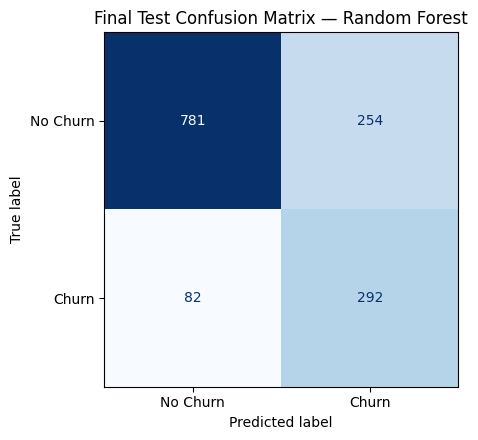

True negatives: 781 | False positives: 254 | False negatives: 82 | True positives: 292
False negatives are churners the model missed; false positives are non-churners flagged as at risk.


In [45]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_test_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    ax=ax,
    colorbar=False,
)
ax.set_title(f"Final Test Confusion Matrix — {selected_model_name}")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred, labels=[0, 1]).ravel()
print(f"True negatives: {tn} | False positives: {fp} | False negatives: {fn} | True positives: {tp}")
print("False negatives are churners the model missed; false positives are non-churners flagged as at risk.")

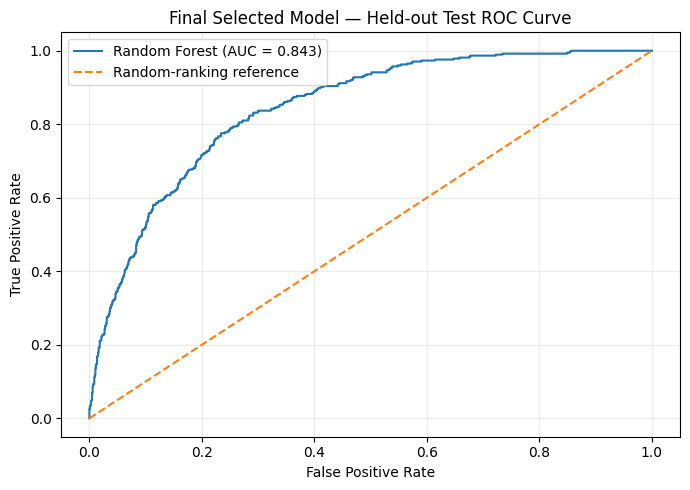

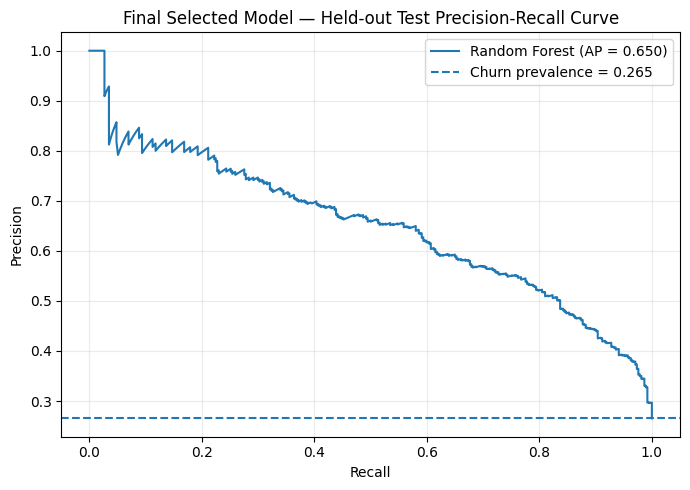

The dashed reference equals the churn prevalence in this hold-out sample. AP summarises the precision-recall curve.


In [46]:
# ROC curve for the selected model only.
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{selected_model_name} (AUC = {final_test_metrics['Test ROC-AUC']:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random-ranking reference")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Final Selected Model — Held-out Test ROC Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

# Precision-recall curve, especially informative when churn is the minority class.
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test, y_test_prob)
positive_prevalence = float(np.mean(y_test))
plt.figure(figsize=(7, 5))
plt.plot(pr_recall, pr_precision, label=f"{selected_model_name} (AP = {final_test_metrics['Test Average Precision (AP)']:.3f})")
plt.axhline(positive_prevalence, linestyle="--", label=f"Churn prevalence = {positive_prevalence:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Selected Model — Held-out Test Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print("The dashed reference equals the churn prevalence in this hold-out sample. AP summarises the precision-recall curve.")

## 10. Model interpretation and probability calibration

Interpretation below is post-selection. It is used to understand the selected model, not to reselect the model or tune it using the hold-out set. Feature associations are predictive/descriptive and must not be presented as causal effects.

Because predicted probabilities may be used to prioritise customers, the next cell checks calibration as well as ranking. The Brier score is a summary of squared probability error (lower is better); the calibration curve compares average predicted probability with the observed churn fraction in bins. These are descriptive hold-out diagnostics, not a claim that the model is ready for operational deployment.

,Feature,Mean ROC-AUC decrease,Std
14,Contract,0.0504,0.0047
4,tenure,0.0155,0.0009
7,InternetService,0.0152,0.0063
19,TenureGroup,0.0087,0.0016
18,TotalCharges,0.0076,0.0012
8,OnlineSecurity,0.0044,0.0023
11,TechSupport,0.0031,0.0008
16,PaymentMethod,0.0024,0.0014
15,PaperlessBilling,0.0012,0.0015
12,StreamingTV,0.0011,0.0011


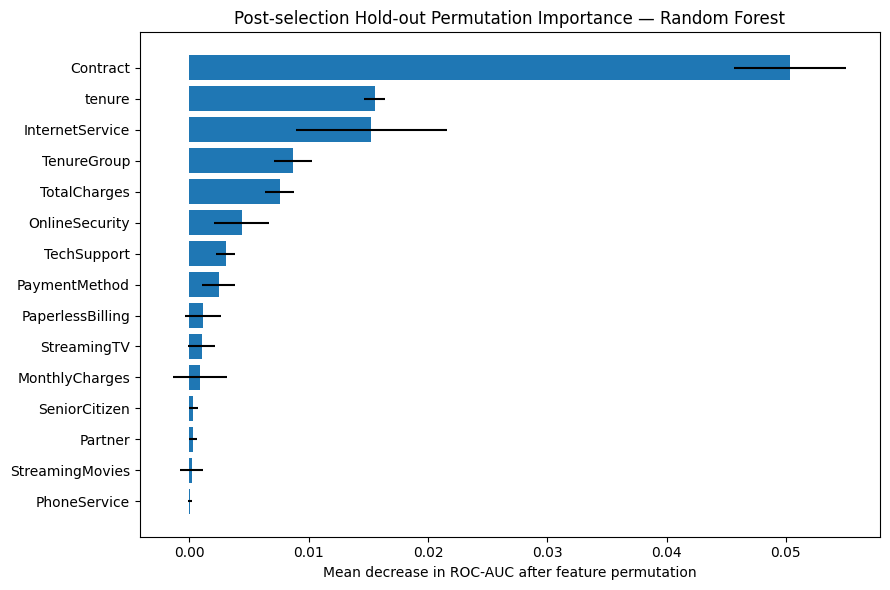

Importance is model-specific and descriptive; it does not establish causation or justify changing the selected model.


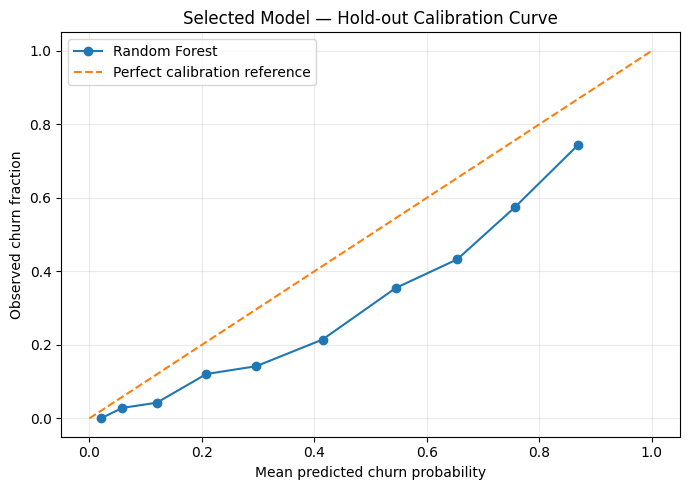

Hold-out Brier score: 0.1579 (lower is better).
Calibration bins may be noisy because the hold-out set is finite; interpret the plot cautiously.


In [47]:
# Model-agnostic permutation importance on the hold-out set, performed after model selection.
# This is a pre-declared descriptive interpretation step only; do not use it to revise model choice or tuning.
perm = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean ROC-AUC decrease": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Mean ROC-AUC decrease", ascending=False)

display(importance_df.head(15).round(4))

plot_importance = importance_df.head(15).sort_values("Mean ROC-AUC decrease")
plt.figure(figsize=(9, 6))
plt.barh(plot_importance["Feature"], plot_importance["Mean ROC-AUC decrease"], xerr=plot_importance["Std"])
plt.xlabel("Mean decrease in ROC-AUC after feature permutation")
plt.title(f"Post-selection Hold-out Permutation Importance — {selected_model_name}")
plt.tight_layout()
plt.show()
print("Importance is model-specific and descriptive; it does not establish causation or justify changing the selected model.")

# Calibration curve and Brier score: predicted probabilities versus observed frequency.
prob_true, prob_pred = calibration_curve(
    y_test,
    y_test_prob,
    n_bins=10,
    strategy="quantile",
)
plt.figure(figsize=(7, 5))
plt.plot(prob_pred, prob_true, marker="o", label=f"{selected_model_name}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration reference")
plt.xlabel("Mean predicted churn probability")
plt.ylabel("Observed churn fraction")
plt.title("Selected Model — Hold-out Calibration Curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()
print(f"Hold-out Brier score: {final_test_metrics['Test Brier Score']:.4f} (lower is better).")
print("Calibration bins may be noisy because the hold-out set is finite; interpret the plot cautiously.")

## 11. Secondary lens — high-risk customer profiling

Use the selected model's predicted probabilities for the hold-out customers to form a **descriptive higher-risk quartile**. This shows how the primary churn-risk output can support customer review. The 75th-percentile cutoff is an exploratory profiling rule, **not** an operational threshold and not a decision rule tuned to actual hold-out labels.

This profiling step uses actual hold-out labels only to summarise the observed churn rate after model selection. The profile is descriptive and must not be used to alter model choice, hyperparameters, or the model-selection rule.

In [48]:
# Profile the selected model's hold-out customers. The risk assignment uses predicted probabilities only.
test_profile = df_model_full.loc[X_test.index].copy()
test_profile["ActualChurn"] = y_test
# Use the model probability associated with each hold-out row.
test_profile["PredictedChurnProbability"] = y_test_prob

risk_cutoff = float(test_profile["PredictedChurnProbability"].quantile(0.75))
test_profile["RiskProfile"] = np.where(
    test_profile["PredictedChurnProbability"] >= risk_cutoff,
    "Higher-risk quartile",
    "Lower-risk 75%",
)

print(f"Descriptive 75th-percentile probability cutoff: {risk_cutoff:.4f}")
display(test_profile["RiskProfile"].value_counts().to_frame("Customers"))

profile_summary = test_profile.groupby("RiskProfile").agg(
    Customer_count=("customerID", "count"),
    Observed_churn_rate=("ActualChurn", "mean"),
    Mean_tenure=("tenure", "mean"),
    Median_tenure=("tenure", "median"),
    Mean_monthly_charges=("MonthlyCharges", "mean"),
    Mean_total_charges=("TotalCharges", "mean"),
).round(3)
display(profile_summary)

print("These are post-selection descriptive summaries of the hold-out profile. They do not show that any characteristic causes churn.")

Descriptive 75th-percentile probability cutoff: 0.6577


,Customers
RiskProfile,
Lower-risk 75%,1056
Higher-risk quartile,353


,Customer_count,Observed_churn_rate,Mean_tenure,Median_tenure,Mean_monthly_charges,Mean_total_charges
RiskProfile,,,,,,
Higher-risk quartile,353,0.626,10.830,5.0,77.179,958.723
Lower-risk 75%,1056,0.145,38.964,41.0,59.713,2616.750


These are post-selection descriptive summaries of the hold-out profile. They do not show that any characteristic causes churn.


In [49]:
for column in ["Contract", "InternetService", "PaymentMethod"]:
    print(f"\n{column} distribution within each risk profile (%)")
    display(pd.crosstab(
        test_profile["RiskProfile"],
        test_profile[column],
        normalize="index",
    ).mul(100).round(1))

high_rate = profile_summary.loc["Higher-risk quartile", "Observed_churn_rate"]
low_rate = profile_summary.loc["Lower-risk 75%", "Observed_churn_rate"]
print(f"Observed churn rate in higher-risk quartile: {high_rate:.1%}")
print(f"Observed churn rate in lower-risk 75%: {low_rate:.1%}")


Contract distribution within each risk profile (%)


Contract,Month-to-month,One year,Two year
RiskProfile,,,
Higher-risk quartile,100.0,0.0,0.0
Lower-risk 75%,39.8,28.4,31.8



InternetService distribution within each risk profile (%)


InternetService,DSL,Fiber optic,No
RiskProfile,,,
Higher-risk quartile,17.6,82.4,0.0
Lower-risk 75%,40.0,30.5,29.5



PaymentMethod distribution within each risk profile (%)


PaymentMethod,Bank transfer (automatic),Credit card (automatic),Electronic check,Mailed check
RiskProfile,,,,
Higher-risk quartile,7.6,10.5,68.3,13.6
Lower-risk 75%,25.9,25.8,22.1,26.3


Observed churn rate in higher-risk quartile: 62.6%
Observed churn rate in lower-risk 75%: 14.5%


### Interpretation guide

Describe the actual output above in your final report. For example, state whether the higher-risk quartile has shorter tenure or a different contract mix **only if the output supports that statement**. Avoid inserting expected results by hand. The profile is meant to support retention review; its probability cutoff must be validated against capacity, intervention cost and false-positive/false-negative consequences before operational use.

## 12. Recommendation and limitations

The recommendation should follow from the **training-CV model comparison, selected model's final hold-out metrics, calibration diagnostics, and secondary descriptive profile**. The model-selection metric remains mean CV ROC-AUC; Average Precision and recall/F1 provide complementary context. A tiny numerical lead on one metric should not be overstated as a conclusive or statistically significant win.

For a practical next step, use scores to prioritise a human review or a small retention pilot rather than contacting customers automatically. Before deployment, define what counts as a useful contact, estimate intervention/contact costs and the cost of missed churners, assess calibration and capacity, and choose any operational threshold using separate validation data—not this final hold-out set.

In [50]:
print("FINAL MODEL SUMMARY")
print("=" * 72)
print("Selected tuned model:", selected_model_name)
print("Selection basis: highest mean 5-fold training CV ROC-AUC within the declared search grids.")
print(f"Best CV ROC-AUC: {float(selected_row['Best CV ROC-AUC']):.4f}")
print(f"CV Average Precision (AP): {float(selected_row['Best CV Average Precision (AP)']):.4f}")
print("Final hold-out metrics:")
for metric in [
    "Test Accuracy", "Test Precision", "Test Recall", "Test F1",
    "Test ROC-AUC", "Test Average Precision (AP)", "Test Brier Score",
]:
    print(f"  {metric}: {final_test_metrics[metric]:.4f}")
print("\nOperational interpretation:")
print("Use predicted risk to prioritise customers for human retention review, not as a guarantee of churn.")
print("Do not treat the highest-scoring model as automatically best for the business; confirm the error-cost trade-off.")
print("Thresholds should be justified using separate validation data, retention capacity, contact costs, and costs of missed churners.")

FINAL MODEL SUMMARY
Selected tuned model: Random Forest
Selection basis: highest mean 5-fold training CV ROC-AUC within the declared search grids.
Best CV ROC-AUC: 0.8479
CV Average Precision (AP): 0.6628
Final hold-out metrics:
  Test Accuracy: 0.7615
  Test Precision: 0.5348
  Test Recall: 0.7807
  Test F1: 0.6348
  Test ROC-AUC: 0.8431
  Test Average Precision (AP): 0.6499
  Test Brier Score: 0.1579

Operational interpretation:
Use predicted risk to prioritise customers for human retention review, not as a guarantee of churn.
Do not treat the highest-scoring model as automatically best for the business; confirm the error-cost trade-off.
Thresholds should be justified using separate validation data, retention capacity, contact costs, and costs of missed churners.


### Limitations

1. The dataset is a snapshot of a particular telecom customer population and may not generalise to other providers or later periods.
2. The label records observed churn; it does not measure whether a particular retention intervention would prevent churn.
3. EDA and model interpretation describe associations and predictions, not causal effects.
4. The selected configuration is chosen from finite parameter grids using training-data cross-validation; the best CV score can be optimistic after search.
5. The final evaluation uses one stratified hold-out set. Future-period or external validation is still needed before operational deployment.
6. The target is imbalanced, so accuracy alone is not enough. Recall, precision, F1, ROC-AUC and Average Precision provide complementary views; the confusion matrix shows errors at the estimator's default decision rule.
7. Brier score and a calibration curve help assess probabilities, but estimates from one hold-out set are uncertain and are not a substitute for external calibration validation.
8. The default classification rule is not necessarily optimal for the business. A practical threshold depends on retention capacity and business costs and should be assessed without tuning on the final hold-out set.
9. Customer behaviour and market conditions can change; monitoring for drift and reassessing the model would be necessary if deployed.

## 13. Reproducibility, saved evidence and AI-use transparency

The following cell saves the initial CV comparison, tuned CV comparison, the selected model's final hold-out metrics, permutation importance, engineered-feature inventory, and SHA-256 fingerprint. These outputs help keep the final notebook, evaluation log and report aligned. Record the actual dataset source and file hash from this run.



In [51]:
# Save generated evidence tables to the current notebook working directory.
initial_cv_results.to_csv("initial_cv_model_comparison.csv", index=False)
tuned_cv_results.to_csv("tuned_cv_model_comparison.csv", index=False)
final_test_results.to_csv("selected_model_final_test_metrics.csv", index=False)
importance_df.to_csv("selected_model_permutation_importance.csv", index=False)
engineered_feature_summary.to_csv("engineered_feature_summary.csv", index=False)

dataset_fingerprint = pd.DataFrame([{
    "Dataset filename": str(dataset_path),
    "SHA-256": dataset_sha256,
    "Rows": int(df_raw.shape[0]),
    "Columns": int(df_raw.shape[1]),
    "Random state": RANDOM_STATE,
    "Selected model": selected_model_name,
    "Feature count including engineered features": int(X.shape[1]),
}])
dataset_fingerprint.to_csv("dataset_and_run_fingerprint.csv", index=False)

display(dataset_fingerprint)
print("Saved: initial_cv_model_comparison.csv")
print("Saved: tuned_cv_model_comparison.csv")
print("Saved: selected_model_final_test_metrics.csv")
print("Saved: selected_model_permutation_importance.csv")
print("Saved: engineered_feature_summary.csv")
print("Saved: dataset_and_run_fingerprint.csv")

,Dataset filename,SHA-256,Rows,Columns,Random state,Selected model,Feature count including engineered features
0,WA_Fn-UseC_-Telco-Customer-Churn (2).csv,88be4b93fbe0cc83421af1c503794c97c342eca914c157...,7043,21,42,Random Forest,21


Saved: initial_cv_model_comparison.csv
Saved: tuned_cv_model_comparison.csv
Saved: selected_model_final_test_metrics.csv
Saved: selected_model_permutation_importance.csv
Saved: engineered_feature_summary.csv
Saved: dataset_and_run_fingerprint.csv


### AI-use transparency

AI tools were used to support the development and refinement of the notebook, including code debugging, improving implementation quality, enhancing model evaluation, and refining technical explanations. The group actively worked on the project, made analytical and implementation decisions, and reviewed the results in line with the project objectives. AI-generated suggestions were treated as supporting resources, with responsibility for the final implementation, verification of results, and submitted work remaining with the group.